# Лабораторная работа: глубокая кластеризация датасета Dry Bean

В ноутбуке выполняются загрузка и анализ данных, предобработка, обучение DEC, VaDE и SOM,
сравнение с K-means, Gaussian Mixture и DBSCAN, а также оценка качества кластеризации.

**Важно:** модели обучаются без использования столбца `Class`. Он применяется только для
внешней оценки и анализа соответствия найденных кластеров исходным классам.

## 1. Установка и импорт библиотек
Если библиотек не хватает, раскомментируйте установку и выполните ячейку.

In [18]:
import os, glob, zipfile, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score)
from scipy.optimize import linear_sum_assignment
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

## 2. Загрузка датасета
Поместите `Dry_Bean_Dataset.xlsx` или ZIP-архив с ним рядом с ноутбуком. Если файл лежит в другой папке, укажите путь в `DATA_PATH`.

In [19]:
DATA_PATH = "Dry_Bean_Dataset.xlsx"
df = pd.read_excel(DATA_PATH)

print("Размер таблицы:", df.shape)
display(df.head())

Размер таблицы: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 3. Первичный анализ

In [20]:
print(df.info())
display(df.describe(include="all").T)
print("Пропуски по столбцам:")
display(df.isna().sum().to_frame("missing"))
print("Дубликаты:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Area,13611.0,NaN,NaN,NaN,53048.284549,29324.095717,20420.0,36328.0,44652.0,61332.0,254616.0
Perimeter,13611.0,NaN,NaN,NaN,855.283459,214.289696,524.736,703.5235,794.941,977.213,1985.37
MajorAxisLength,13611.0,NaN,NaN,NaN,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,NaN,NaN,NaN,202.270714,44.970091,122.512653,175.84817,192.431733,217.031741,460.198497
AspectRation,13611.0,NaN,NaN,NaN,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,NaN,NaN,NaN,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,NaN,NaN,NaN,53768.200206,29774.915817,20684.0,36714.5,45178.0,62294.0,263261.0
EquivDiameter,13611.0,NaN,NaN,NaN,253.06422,59.17712,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,NaN,NaN,NaN,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,NaN,NaN,NaN,0.987143,0.00466,0.919246,0.98567,0.988283,0.990013,0.994677


Пропуски по столбцам:


,missing
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRation,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


Дубликаты: 68


Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


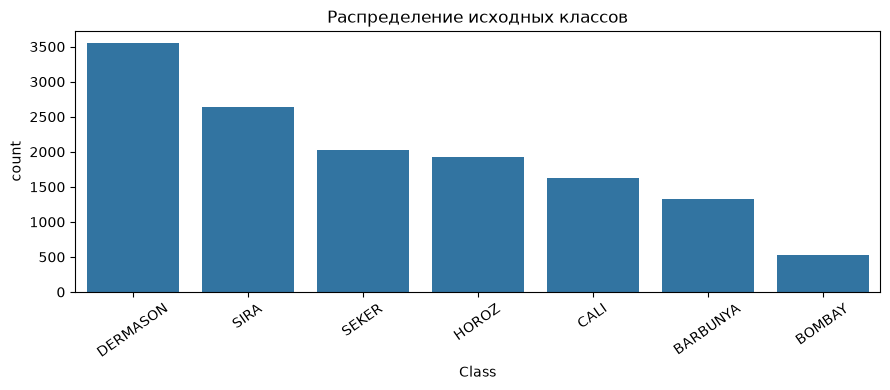

In [21]:
if "Class" not in df.columns:
    raise ValueError("Ожидается столбец Class с исходными классами фасоли.")
print(df["Class"].value_counts())
plt.figure(figsize=(9,4))
sns.countplot(data=df, x="Class", order=df["Class"].value_counts().index)
plt.xticks(rotation=35)
plt.title("Распределение исходных классов")
plt.tight_layout()
plt.show()

## 4. Предобработка данных
Удаляем дубликаты, отделяем метки классов и стандартизируем числовые признаки.

In [22]:
df = df.drop_duplicates().reset_index(drop=True)
y_text = df["Class"].astype(str)
X_df = df.drop(columns=["Class"]).select_dtypes(include=[np.number]).copy()
X_df = X_df.replace([np.inf, -np.inf], np.nan)
X_df = X_df.fillna(X_df.median(numeric_only=True))
X = X_df.to_numpy(dtype=np.float32)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype(np.float32)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)
n_clusters = len(np.unique(y))
print("Объектов:", len(X_scaled), "| признаков:", X_scaled.shape[1], "| классов:", n_clusters)

Объектов: 13543 | признаков: 16 | классов: 7


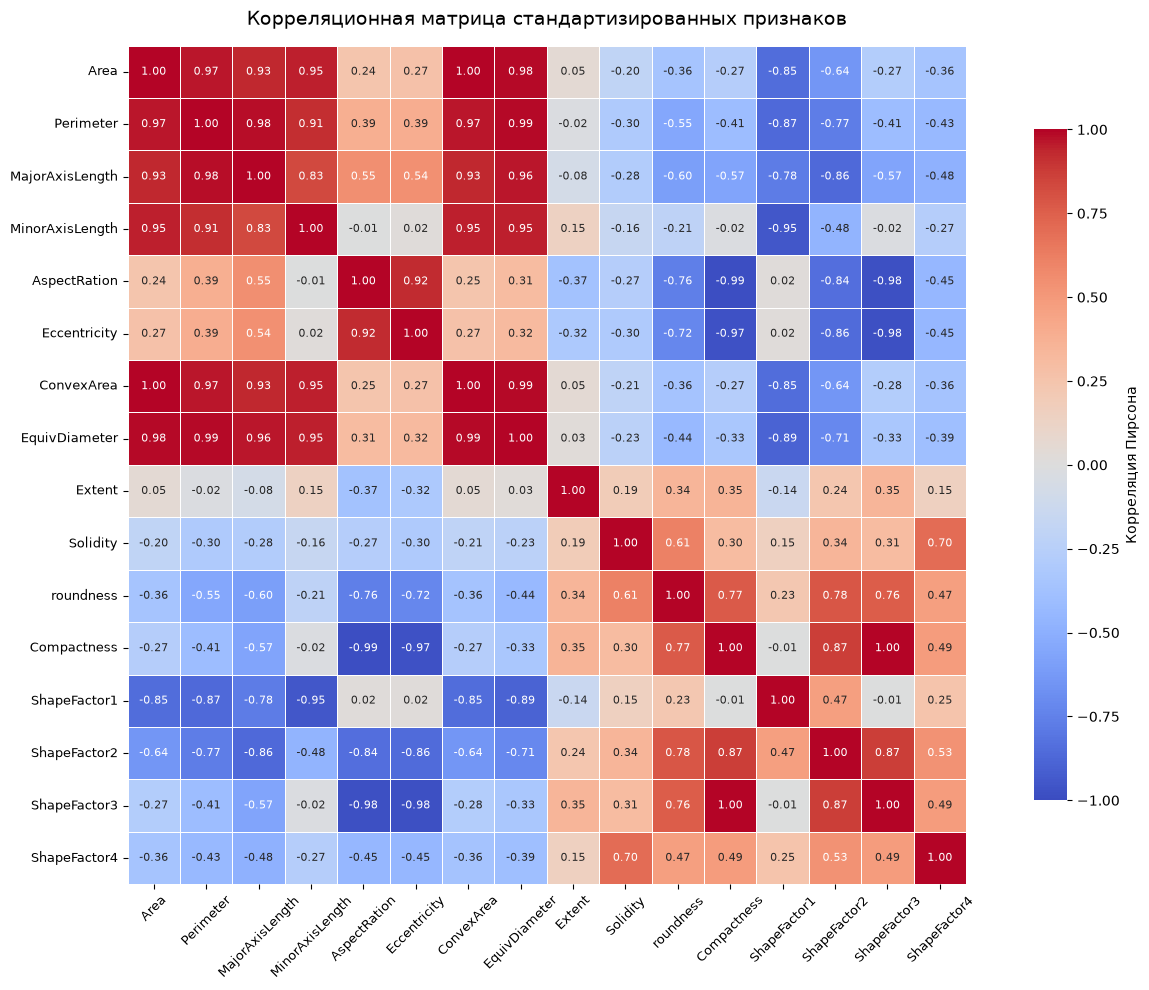

In [23]:
corr = pd.DataFrame(X_scaled, columns=X_df.columns).corr()
mask_upper = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(14, 10))
ax = sns.heatmap(
    corr,
    annot=True,               # цифры внутри ячеек
    fmt=".2f",                # два знака после запятой
    cmap="coolwarm",          # расходящаяся палитра
    center=0,                 # 0 — нейтральный цвет
    vmin=-1, vmax=1,          # фиксированный диапазон
    square=True,              # квадратные ячейки
    linewidths=0.5,           # толщина границ
    linecolor="white",        # цвет границ
    cbar_kws={"shrink": 0.8, "label": "Корреляция Пирсона"},
    annot_kws={"size": 8},
)

ax.set_title("Корреляционная матрица стандартизированных признаков",
             fontsize=14, pad=15)
ax.tick_params(axis="x", rotation=45, labelsize=9)
ax.tick_params(axis="y", rotation=0, labelsize=9)
plt.tight_layout()
plt.show()

## 5. Визуализация исходных данных методом PCA

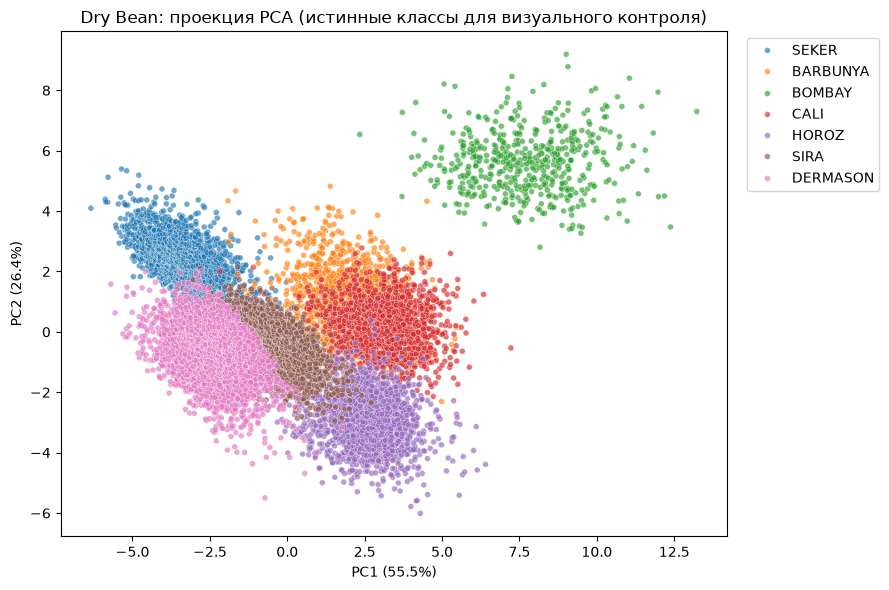

In [24]:
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize=(9,6))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=y_text, s=18, alpha=.65, palette="tab10")
plt.title("Dry Bean: проекция PCA (истинные классы для визуального контроля)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.legend(bbox_to_anchor=(1.02,1), loc="upper left")
plt.tight_layout()
plt.show()

## 6. Функции оценки качества
Внутренние метрики рассчитываются по признакам и предсказанным кластерам. ARI и NMI используют истинные метки только для внешней оценки.

In [25]:
def clustering_metrics(X_data, labels, y_true=None):
    labels = np.asarray(labels)
    valid = labels != -1
    unique = np.unique(labels[valid])
    result = {"n_clusters": len(unique), "noise_fraction": float(np.mean(~valid))}
    if len(unique) < 2 or valid.sum() <= len(unique):
        result.update(silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan)
    else:
        result["silhouette"] = silhouette_score(X_data[valid], labels[valid])
        result["davies_bouldin"] = davies_bouldin_score(X_data[valid], labels[valid])
        result["calinski_harabasz"] = calinski_harabasz_score(X_data[valid], labels[valid])
    if y_true is not None:
        result["ARI"] = adjusted_rand_score(y_true, labels)
        result["NMI"] = normalized_mutual_info_score(y_true, labels)
    return result

def best_label_accuracy(y_true, y_pred):
    # Максимальная точность после оптимального сопоставления номеров кластеров и классов.
    yt = LabelEncoder().fit_transform(y_true)
    yp = LabelEncoder().fit_transform(y_pred)
    contingency = np.zeros((max(yt.max(), yp.max())+1, max(yt.max(), yp.max())+1), dtype=int)
    for a,b in zip(yt, yp):
        contingency[a,b] += 1
    r,c = linear_sum_assignment(contingency.max() - contingency)
    return contingency[r,c].sum()/len(yt)

## 7. Базовые алгоритмы кластеризации

In [26]:
baseline_results = []
baseline_labels = {}

km = KMeans(n_clusters=n_clusters, n_init=20, random_state=SEED)
baseline_labels["K-means"] = km.fit_predict(X_scaled)

gmm = GaussianMixture(n_components=n_clusters, covariance_type="full",
                      random_state=SEED, n_init=3)
baseline_labels["GMM"] = gmm.fit_predict(X_scaled)

# DBSCAN чувствителен к eps и min_samples; параметры ниже — стартовая конфигурация.
db = DBSCAN(eps=1.8, min_samples=10)
baseline_labels["DBSCAN"] = db.fit_predict(X_scaled)

for name, labels in baseline_labels.items():
    row = {"method": name, **clustering_metrics(X_scaled, labels, y)}
    baseline_results.append(row)
display(pd.DataFrame(baseline_results))

,method,n_clusters,noise_fraction,silhouette,davies_bouldin,calinski_harabasz,ARI,NMI
0,K-means,7,0.000000,0.308842,1.101123,7787.857771,0.667898,0.712903
1,GMM,7,0.000000,0.289469,1.661013,6388.514316,0.680638,0.732216
2,DBSCAN,1,0.008565,NaN,NaN,NaN,0.000919,0.004116


## 8. Глубокая кластеризация: общая подготовка
Для DEC и VaDE используется компактный автоэнкодер. PyTorch необходим для этих разделов.

In [27]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)

Устройство: cpu


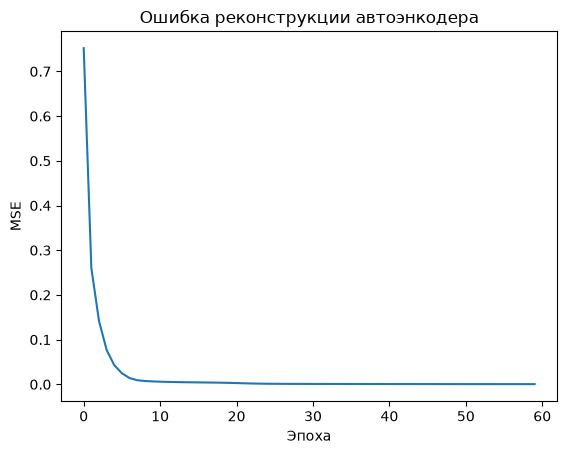

In [28]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=10):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, latent_dim))
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32), nn.ReLU(),
            nn.Linear(32, 64), nn.ReLU(),
            nn.Linear(64, input_dim))
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

def train_autoencoder(model, X_tensor, epochs=60, batch_size=256, lr=1e-3):
    model.to(device)
    loader = DataLoader(TensorDataset(X_tensor), batch_size=batch_size, shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    history = []
    for epoch in range(epochs):
        model.train()
        losses = []
        for (batch,) in loader:
            batch = batch.to(device)
            recon, _ = model(batch)
            loss = loss_fn(recon, batch)
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
        history.append(np.mean(losses))
    return history

LATENT_DIM = 10
ae = Autoencoder(X_scaled.shape[1], LATENT_DIM)
ae_history = train_autoencoder(ae, X_tensor)
plt.plot(ae_history); plt.title("Ошибка реконструкции автоэнкодера"); plt.xlabel("Эпоха"); plt.ylabel("MSE"); plt.show()

## 9. DEC — Deep Embedded Clustering
DEC уточняет представления объектов и центры кластеров с помощью целевого распределения.

In [29]:
class DEC(nn.Module):
    def __init__(self, encoder, n_clusters, alpha=1.0):
        super().__init__()
        self.encoder = encoder
        self.alpha = alpha
        self.centers = nn.Parameter(torch.randn(n_clusters, LATENT_DIM))
    def forward(self, x):
        z = self.encoder(x)
        dist = torch.sum((z[:,None,:] - self.centers[None,:,:])**2, dim=2)
        q = (1 + dist/self.alpha).pow(-(self.alpha+1)/2)
        q = q / q.sum(dim=1, keepdim=True)
        return q, z

def target_distribution(q):
    weight = q**2 / q.sum(0)
    return (weight.T / weight.sum(1)).T

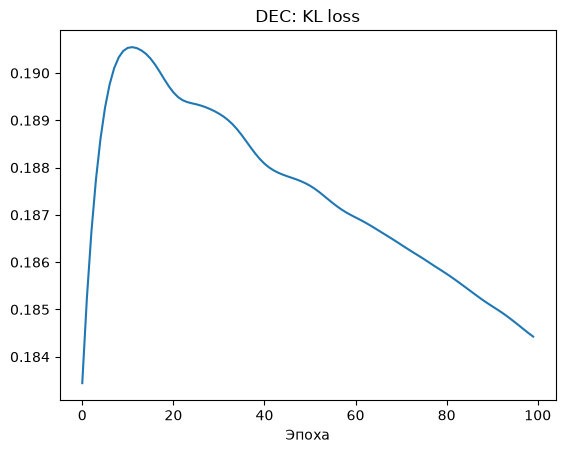

In [30]:
dec = DEC(ae.encoder, n_clusters).to(device)
with torch.no_grad():
    z0 = ae.encoder(X_tensor.to(device)).cpu().numpy()
dec_init = KMeans(n_clusters=n_clusters, n_init=20, random_state=SEED).fit(z0)
dec.centers.data = torch.tensor(dec_init.cluster_centers_, dtype=torch.float32, device=device)
opt = torch.optim.Adam(dec.parameters(), lr=1e-3)
dec_losses = []
Xt = X_tensor.to(device)
for epoch in range(100):
    q, _ = dec(Xt)
    p = target_distribution(q.detach())
    loss = torch.mean(torch.sum(p * torch.log((p + 1e-8)/(q + 1e-8)), dim=1))
    opt.zero_grad(); loss.backward(); opt.step()
    dec_losses.append(loss.item())
with torch.no_grad():
    q, z_dec = dec(Xt)
    dec_labels = q.argmax(1).cpu().numpy()
plt.plot(dec_losses); plt.title("DEC: KL loss"); plt.xlabel("Эпоха"); plt.show()

## 10. VaDE — Variational Deep Embedding
Упрощённая реализация VaDE: вариационный автоэнкодер с гауссовой смесью в латентном пространстве. Это учебная реализация, а не оптимизированный промышленный вариант.

In [31]:
class VaDE(nn.Module):
    def __init__(self, input_dim, latent_dim, n_clusters):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_dim,64), nn.ReLU(), nn.Linear(64,32), nn.ReLU())
        self.mu = nn.Linear(32, latent_dim)
        self.logvar = nn.Linear(32, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim,32), nn.ReLU(), nn.Linear(32,64), nn.ReLU(), nn.Linear(64,input_dim))
        self.pi_logits = nn.Parameter(torch.zeros(n_clusters))
        self.mu_c = nn.Parameter(torch.randn(n_clusters, latent_dim)*0.2)
        self.logvar_c = nn.Parameter(torch.zeros(n_clusters, latent_dim))
    def forward(self, x):
        h = self.encoder(x); mu = self.mu(h); logvar = self.logvar(h)
        z = mu + torch.randn_like(mu)*torch.exp(0.5*logvar)
        return self.decoder(z), mu, logvar, z
    def responsibilities(self, z):
        var = torch.exp(self.logvar_c).clamp_min(1e-6)
        logp = -0.5 * torch.sum(torch.log(2*np.pi*var)[None,:,:] + (z[:,None,:]-self.mu_c[None,:,:])**2/var[None,:,:], dim=2)
        logp = logp + torch.log_softmax(self.pi_logits, dim=0)[None,:]
        return torch.softmax(logp, dim=1)

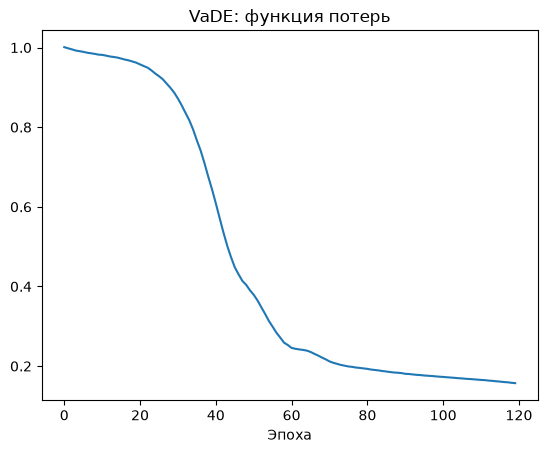

In [32]:
vade = VaDE(X_scaled.shape[1], LATENT_DIM, n_clusters).to(device)
opt = torch.optim.Adam(vade.parameters(), lr=1e-3)
vade_losses = []
for epoch in range(120):
    recon, mu, logvar, z = vade(Xt)
    resp = vade.responsibilities(z)
    recon_loss = nn.functional.mse_loss(recon, Xt)
    # Регуляризация латентного распределения и мягкая кластерная аппроксимация.
    kl_normal = -0.5*torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    entropy_term = torch.mean(torch.sum(resp * torch.log(resp + 1e-8), dim=1))
    loss = recon_loss + 0.01*kl_normal + 0.01*entropy_term
    opt.zero_grad(); loss.backward(); opt.step()
    vade_losses.append(loss.item())
with torch.no_grad():
    _, _, _, zv = vade(Xt)
    vade_labels = vade.responsibilities(zv).argmax(1).cpu().numpy()
plt.plot(vade_losses); plt.title("VaDE: функция потерь"); plt.xlabel("Эпоха"); plt.show()

## 11. SOM — Self-Organizing Map
SOM сохраняет топологические отношения между объектами. Размер карты можно менять.

In [33]:
try:
    from minisom import MiniSom
except ImportError as e:
    raise ImportError("Установите minisom: %pip install minisom") from e

som_x, som_y = 4, 4
som = MiniSom(som_x, som_y, X_scaled.shape[1], sigma=1.2, learning_rate=0.5,
              neighborhood_function="gaussian", random_seed=SEED)
som.random_weights_init(X_scaled)
som.train_random(X_scaled, 5000, verbose=True)

 [ 5000 / 5000 ] 100% - 0:00:00 left 
 quantization error: 2.1165096793821805


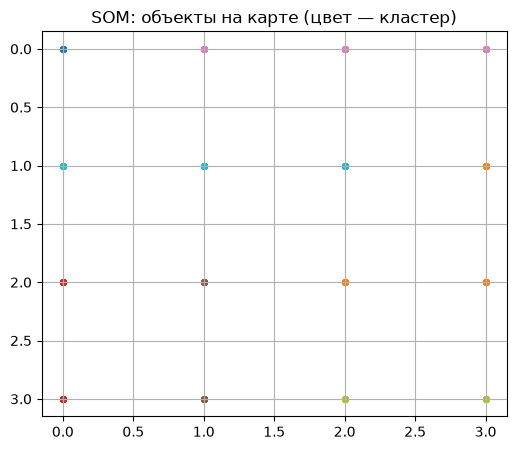

In [34]:
# Группируем нейроны карты в n_clusters кластеров методом K-means.
weights = som.get_weights()
neuron_vectors = weights.reshape(-1, X_scaled.shape[1])
neuron_cluster = KMeans(n_clusters=n_clusters, n_init=20, random_state=SEED).fit_predict(neuron_vectors)
som_labels = np.array([
    neuron_cluster[som.winner(row)[0]*som_y + som.winner(row)[1]]
    for row in X_scaled
])
plt.figure(figsize=(6,5))
for i, row in enumerate(X_scaled):
    wx, wy = som.winner(row)
    plt.scatter(wx, wy, c=[som_labels[i]], cmap="tab10", vmin=0, vmax=n_clusters-1, s=12)
plt.title("SOM: объекты на карте (цвет — кластер)")
plt.gca().invert_yaxis(); plt.grid(); plt.show()

## 12. Сводное сравнение алгоритмов

In [35]:
all_labels = {**baseline_labels, "DEC": dec_labels, "VaDE": vade_labels, "SOM": som_labels}
rows = []
for name, labels in all_labels.items():
    rows.append({"method": name, **clustering_metrics(X_scaled, labels, y),
                 "matched_accuracy": best_label_accuracy(y, labels)})
results = pd.DataFrame(rows).set_index("method")
display(results.sort_values("ARI", ascending=False))

,n_clusters,noise_fraction,silhouette,davies_bouldin,calinski_harabasz,ARI,NMI,matched_accuracy
method,,,,,,,,
GMM,7,0.000000,0.289469,1.661013,6388.514316,0.680638,0.732216,0.817913
K-means,7,0.000000,0.308842,1.101123,7787.857771,0.667898,0.712903,0.786089
DEC,7,0.000000,0.268366,1.330959,6902.900399,0.561581,0.641330,0.753526
SOM,7,0.000000,0.293942,1.206900,5510.184204,0.438817,0.593499,0.586059
VaDE,7,0.000000,-0.073677,13.548188,117.652101,0.031981,0.062120,0.247213
DBSCAN,1,0.008565,NaN,NaN,NaN,0.000919,0.004116,0.264048


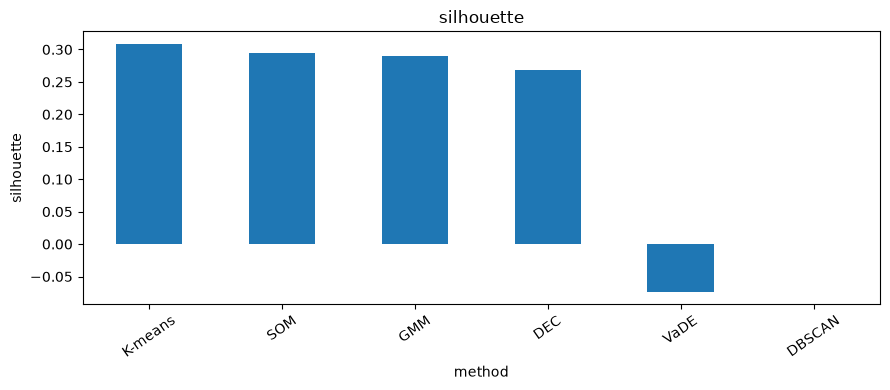

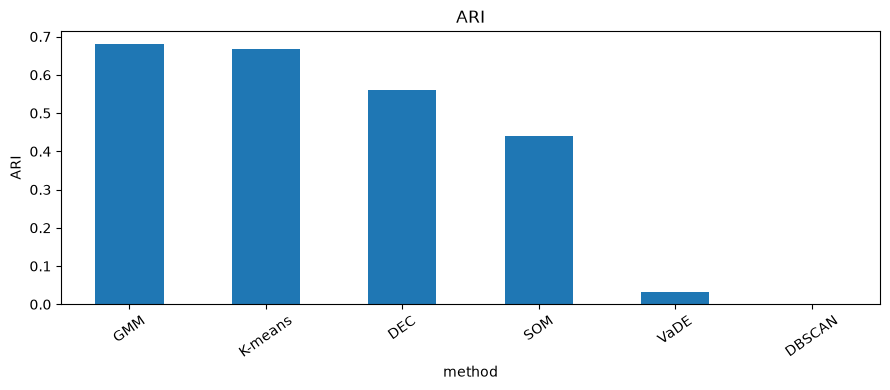

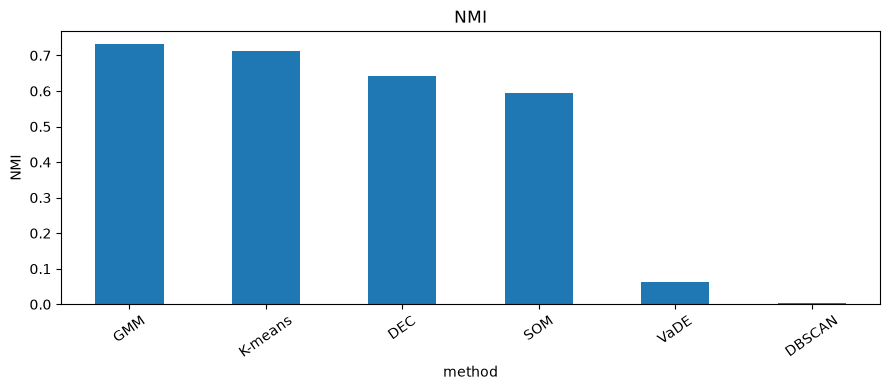

In [36]:
metrics_to_plot = ["silhouette", "ARI", "NMI"]
for metric in metrics_to_plot:
    ax = results[metric].sort_values(ascending=False).plot(kind="bar", figsize=(9,4), title=metric)
    ax.set_ylabel(metric); plt.xticks(rotation=35); plt.tight_layout(); plt.show()

## 13. Визуальное сравнение кластеров в PCA

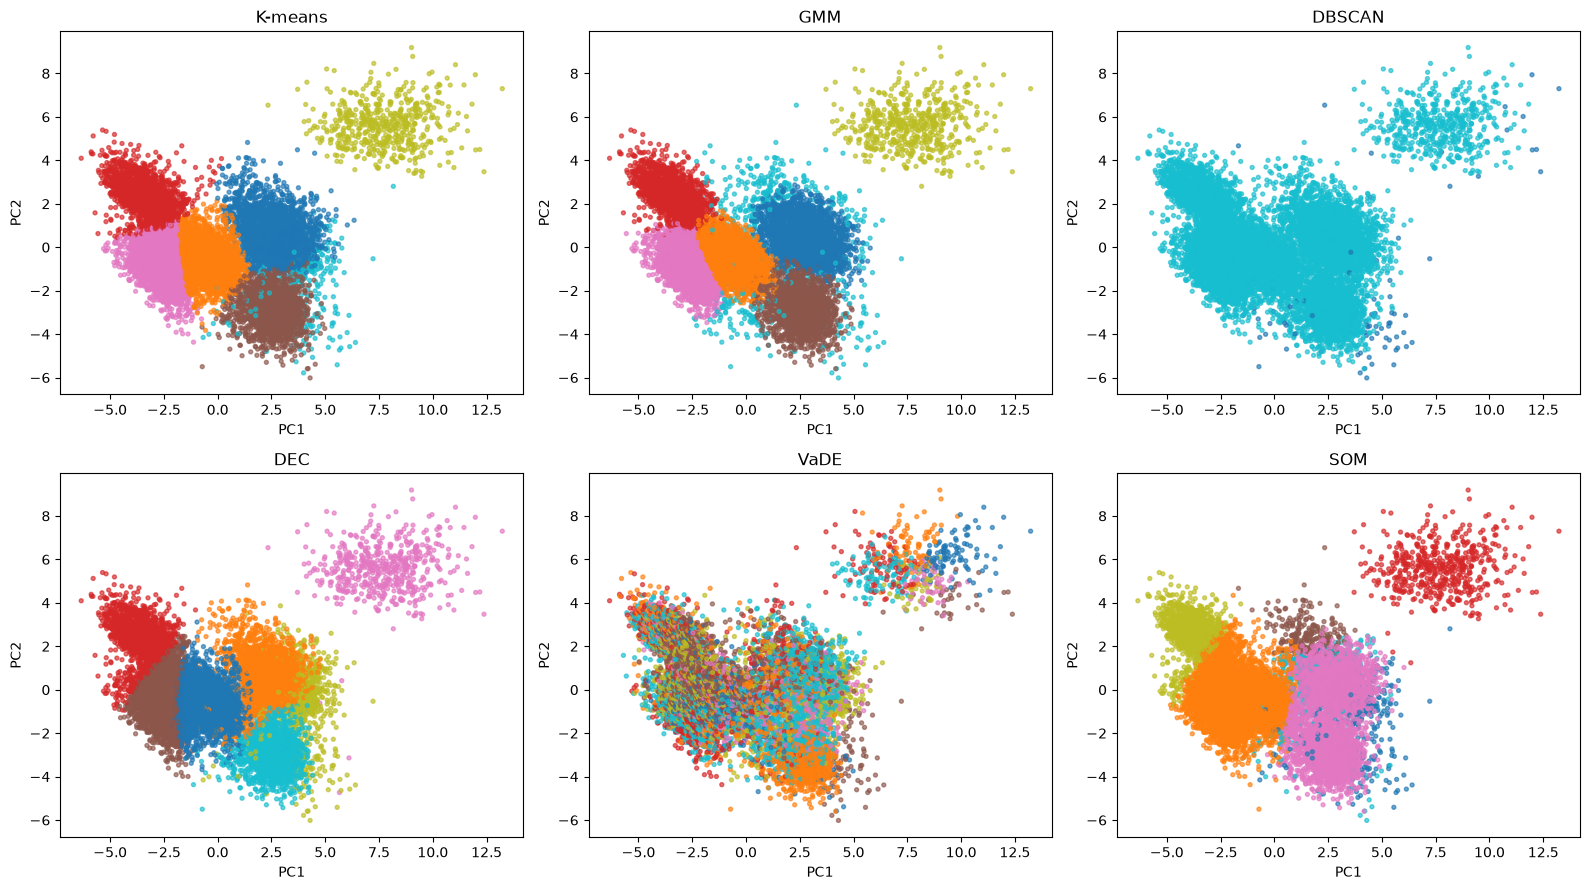

In [37]:
fig, axes = plt.subplots(2, 3, figsize=(16,9))
for ax, (name, labels) in zip(axes.flat, all_labels.items()):
    ax.scatter(X_pca[:,0], X_pca[:,1], c=labels, cmap="tab10", s=8, alpha=.65)
    ax.set_title(name); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
for ax in axes.flat[len(all_labels):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 14. Анализ состава кластеров

In [ ]:
best_method = results["ARI"].idxmax()
best_labels = all_labels[best_method]
cluster_table = pd.crosstab(pd.Series(best_labels, name="Кластер"),
                            pd.Series(label_encoder.inverse_transform(y), name="Исходный класс"),
                            normalize="index")
print("Лучший метод по ARI:", best_method)
display(cluster_table.round(3))

Лучший метод по ARI: GMM


Исходный класс,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
Кластер,,,,,,,
0,0.380,0.000,0.608,0.000,0.009,0.000,0.002
1,0.007,0.000,0.003,0.195,0.009,0.031,0.755
2,0.000,0.000,0.001,0.048,0.000,0.936,0.015
3,0.003,0.000,0.022,0.001,0.929,0.000,0.045
4,0.000,0.000,0.000,0.964,0.002,0.006,0.029
5,0.000,1.000,0.000,0.000,0.000,0.000,0.000
6,0.496,0.003,0.066,0.128,0.177,0.078,0.052


: 